In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load all four datasets

movies = pd.read_csv("dataset/movies.csv")
ratings = pd.read_csv("dataset/ratings.csv")
tags = pd.read_csv("dataset/tags.csv")
links = pd.read_csv("dataset/links.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("Movies Dataset:", movies.shape)
print("Ratings Dataset:", ratings.shape)
print("Tags Dataset:", tags.shape)
print("Links Dataset:", links.shape)

Movies Dataset: (9742, 3)
Ratings Dataset: (100836, 4)
Tags Dataset: (3683, 4)
Links Dataset: (9742, 3)


In [4]:
display(movies.head())
display(ratings.head())
display(tags.head())
display(links.head())

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [5]:
print("MOVIES DATASET")
print(movies.info())

print("\nRATINGS DATASET")
print(ratings.info())

print("\nTAGS DATASET")
print(tags.info())

print("\nLINKS DATASET")
print(links.info())

MOVIES DATASET
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 626.1 KB
None

RATINGS DATASET
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
None

TAGS DATASET
<class 'pandas.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   userId     3683 non-null   int64
 1   movieId    3

In [6]:
print("MOVIES COLUMNS:")
print(movies.columns.tolist())

print("\nRATINGS COLUMNS:")
print(ratings.columns.tolist())

print("\nTAGS COLUMNS:")
print(tags.columns.tolist())

print("\nLINKS COLUMNS:")
print(links.columns.tolist())

MOVIES COLUMNS:
['movieId', 'title', 'genres']

RATINGS COLUMNS:
['userId', 'movieId', 'rating', 'timestamp']

TAGS COLUMNS:
['userId', 'movieId', 'tag', 'timestamp']

LINKS COLUMNS:
['movieId', 'imdbId', 'tmdbId']


In [7]:
print("Missing values in Movies:")
print(movies.isnull().sum())

print("\nMissing values in Ratings:")
print(ratings.isnull().sum())

print("\nMissing values in Tags:")
print(tags.isnull().sum())

print("\nMissing values in Links:")
print(links.isnull().sum())

Missing values in Movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in Ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Missing values in Tags:
userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

Missing values in Links:
movieId    0
imdbId     0
tmdbId     8
dtype: int64


In [8]:
print("Movies duplicates:", movies.duplicated().sum())
print("Ratings duplicates:", ratings.duplicated().sum())
print("Tags duplicates:", tags.duplicated().sum())
print("Links duplicates:", links.duplicated().sum())

Movies duplicates: 0
Ratings duplicates: 0
Tags duplicates: 0
Links duplicates: 0


# EXPLORATORY DATA ANALYSIS

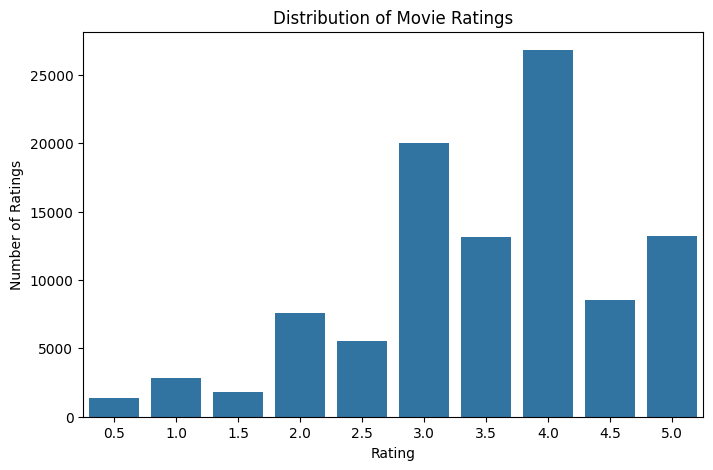

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x="rating"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

In [14]:
movie_rating_counts = ratings["movieId"].value_counts().head(10)

top_movies = movies[
    movies["movieId"].isin(movie_rating_counts.index)
].copy()

top_movies["rating_count"] = (
    top_movies["movieId"].map(movie_rating_counts)
)

top_movies = top_movies.sort_values(
    by="rating_count",
    ascending=False
)

display(top_movies[["title", "rating_count"]])

,title,rating_count
314,Forrest Gump (1994),329
277,"Shawshank Redemption, The (1994)",317
257,Pulp Fiction (1994),307
510,"Silence of the Lambs, The (1991)",279
1939,"Matrix, The (1999)",278
224,Star Wars: Episode IV - A New Hope (1977),251
418,Jurassic Park (1993),238
97,Braveheart (1995),237
507,Terminator 2: Judgment Day (1991),224
461,Schindler's List (1993),220


In [15]:
average_ratings = ratings.groupby("movieId")["rating"].mean()

movie_stats = ratings.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "count")
).reset_index()

movie_stats = movie_stats.merge(
    movies,
    on="movieId"
)

display(
    movie_stats.sort_values(
        by="average_rating",
        ascending=False
    ).head(10)
)

,movieId,average_rating,rating_count,title,genres
9693,187717,5.0,1,Won't You Be My Neighbor? (2018),Documentary
4667,6983,5.0,1,Jane Eyre (1944),Drama|Romance
3802,5328,5.0,1,Rain (2001),Drama|Romance
7927,95843,5.0,1,Goodbye Charlie (1964),Comedy|Fantasy|Romance
2934,3941,5.0,1,Sorority House Massacre (1986),Horror
2933,3940,5.0,1,Slumber Party Massacre III (1990),Horror
2932,3939,5.0,1,Slumber Party Massacre II (1987),Horror
5015,7815,5.0,1,True Stories (1986),Comedy|Musical
9349,162414,5.0,1,Moonlight,Drama
9347,162344,5.0,1,Tom Segura: Mostly Stories (2016),Comedy


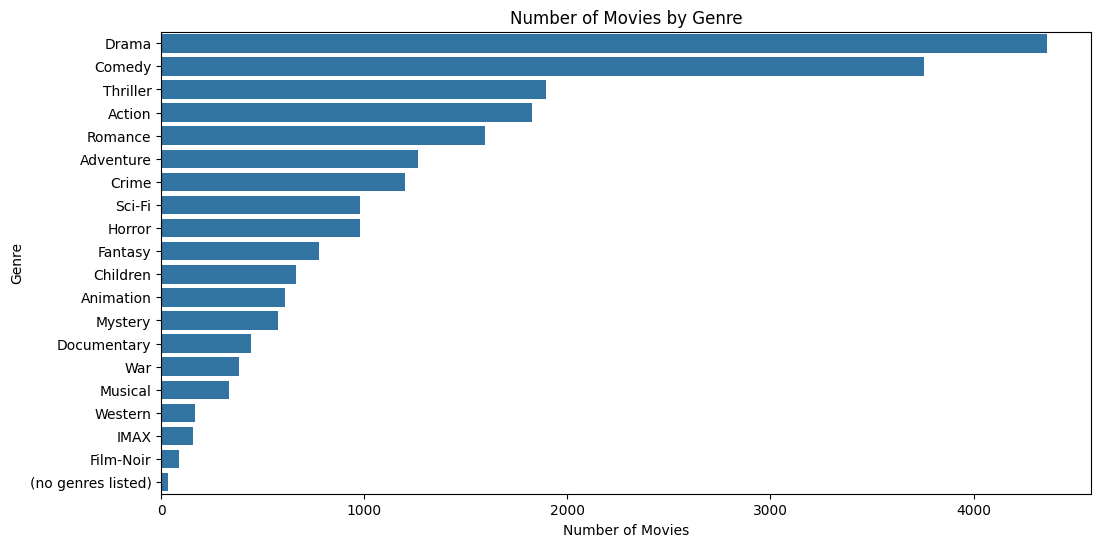

In [16]:
genre_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.show()

In [17]:
# Calculate average rating and rating count
movie_stats = ratings.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "count")
).reset_index()

# Merge movie information
movie_stats = movie_stats.merge(
    movies,
    on="movieId",
    how="left"
)

# Calculate global average rating
C = ratings["rating"].mean()

# Minimum number of ratings required
m = 50

# Calculate weighted rating
movie_stats["weighted_rating"] = (
    (movie_stats["rating_count"] /
     (movie_stats["rating_count"] + m))
    * movie_stats["average_rating"]
    +
    (m / (movie_stats["rating_count"] + m)) * C
)

# Display top 10 movies
top_weighted_movies = movie_stats.sort_values(
    by="weighted_rating",
    ascending=False
)

display(
    top_weighted_movies[
        ["title", "average_rating", "rating_count", "weighted_rating"]
    ].head(10)
)

,title,average_rating,rating_count,weighted_rating
277,"Shawshank Redemption, The (1994)",4.429022,317,4.302664
2224,Fight Club (1999),4.272936,218,4.129022
659,"Godfather, The (1972)",4.289062,192,4.126355
224,Star Wars: Episode IV - A New Hope (1977),4.231076,251,4.109893
257,Pulp Fiction (1994),4.197068,307,4.099658
46,"Usual Suspects, The (1995)",4.237745,204,4.092826
461,Schindler's List (1993),4.225000,220,4.091029
1938,"Matrix, The (1999)",4.192446,278,4.087128
897,Star Wars: Episode V - The Empire Strikes Back...,4.215640,211,4.078842
314,Forrest Gump (1994),4.164134,329,4.076723


In [18]:
# Check unique movie genres

all_genres = set()

for genre_list in movies["genres"]:
    for genre in genre_list.split("|"):
        all_genres.add(genre)

print("Total Unique Genres:", len(all_genres))
print("\nAvailable Genres:")

for genre in sorted(all_genres):
    print(genre)

Total Unique Genres: 20

Available Genres:
(no genres listed)
Action
Adventure
Animation
Children
Comedy
Crime
Documentary
Drama
Fantasy
Film-Noir
Horror
IMAX
Musical
Mystery
Romance
Sci-Fi
Thriller
War
Western


In [19]:
# Replace the genre separator with spaces

movies["genres_clean"] = movies["genres"].str.replace(
    "|", " ", regex=False
)

display(movies[["title", "genres", "genres_clean"]].head(10))

,title,genres,genres_clean
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Adventure Animation Children Comedy Fantasy
1,Jumanji (1995),Adventure|Children|Fantasy,Adventure Children Fantasy
2,Grumpier Old Men (1995),Comedy|Romance,Comedy Romance
3,Waiting to Exhale (1995),Comedy|Drama|Romance,Comedy Drama Romance
4,Father of the Bride Part II (1995),Comedy,Comedy
5,Heat (1995),Action|Crime|Thriller,Action Crime Thriller
6,Sabrina (1995),Comedy|Romance,Comedy Romance
7,Tom and Huck (1995),Adventure|Children,Adventure Children
8,Sudden Death (1995),Action,Action
9,GoldenEye (1995),Action|Adventure|Thriller,Action Adventure Thriller


# TF_IDF Vectorization 

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer()

# Convert movie genres into numerical vectors
tfidf_matrix = tfidf.fit_transform(movies["genres_clean"])

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Total Movies:", len(movies))
print("Total Genre Features:", len(tfidf.get_feature_names_out()))

TF-IDF Matrix Shape: (9742, 24)
Total Movies: 9742
Total Genre Features: 24


# COSINE SIMILARITY

In [21]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate similarity between all movies
cosine_sim = cosine_similarity(tfidf_matrix)

print("Cosine Similarity Matrix Shape:", cosine_sim.shape)
print("Similarity calculation completed!")

Cosine Similarity Matrix Shape: (9742, 9742)
Similarity calculation completed!


In [22]:
# Create a mapping of movie titles to their index
movie_indices = pd.Series(
    movies.index,
    index=movies["title"]
).drop_duplicates()

# Recommendation function
def recommend_movies(movie_name, num_recommendations=10):

    # Check whether movie exists
    if movie_name not in movie_indices:
        print("Movie not found in dataset!")
        return

    # Get movie index
    idx = movie_indices[movie_name]

    # Get similarity scores
    similarity_scores = list(enumerate(cosine_sim[idx]))

    # Sort movies by similarity score
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Exclude the selected movie itself
    similarity_scores = similarity_scores[1:num_recommendations + 1]

    # Get recommended movie indices
    movie_indices_list = [i[0] for i in similarity_scores]

    # Display recommendations
    recommendations = movies.iloc[movie_indices_list][
        ["title", "genres"]
    ].copy()

    recommendations["similarity_score"] = [
        round(score, 3) for _, score in similarity_scores
    ]

    return recommendations

In [23]:
recommend_movies("Toy Story (1995)")

,title,genres,similarity_score
1706,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
2355,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
2809,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3000,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3568,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0
6194,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
6486,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
6948,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,1.0
7760,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,1.0
8219,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0


In [24]:
display(tags.head(10))

print("Total Tags:", len(tags))
print("Unique Movies:", tags["movieId"].nunique())

,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200
5,2,89774,Tom Hardy,1445715205
6,2,106782,drugs,1445715054
7,2,106782,Leonardo DiCaprio,1445715051
8,2,106782,Martin Scorsese,1445715056
9,7,48516,way too long,1169687325


Total Tags: 3683
Unique Movies: 1572


In [25]:
movie_tags = tags.groupby("movieId")["tag"].apply(
    lambda x: " ".join(x.astype(str))
).reset_index()

movie_tags.rename(
    columns={"tag": "movie_tags"},
    inplace=True
)

display(movie_tags.head())

,movieId,movie_tags
0,1,pixar pixar fun
1,2,fantasy magic board game Robin Williams game
2,3,moldy old
3,5,pregnancy remake
4,7,remake


In [26]:
movies = movies.merge(
    movie_tags,
    on="movieId",
    how="left"
)

movies["movie_tags"] = movies["movie_tags"].fillna("")

display(movies[["title", "genres", "movie_tags"]].head(10))

,title,genres,movie_tags
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,pixar pixar fun
1,Jumanji (1995),Adventure|Children|Fantasy,fantasy magic board game Robin Williams game
2,Grumpier Old Men (1995),Comedy|Romance,moldy old
3,Waiting to Exhale (1995),Comedy|Drama|Romance,
4,Father of the Bride Part II (1995),Comedy,pregnancy remake
5,Heat (1995),Action|Crime|Thriller,
6,Sabrina (1995),Comedy|Romance,remake
7,Tom and Huck (1995),Adventure|Children,
8,Sudden Death (1995),Action,
9,GoldenEye (1995),Action|Adventure|Thriller,


In [27]:
# Combine genres and tags into one text feature

movies["combined_features"] = (
    movies["genres"]
    .fillna("")
    .str.replace("|", " ", regex=False)
    + " "
    + movies["movie_tags"].fillna("")
)

display(
    movies[["title", "combined_features"]].head(10)
)

,title,combined_features
0,Toy Story (1995),Adventure Animation Children Comedy Fantasy pi...
1,Jumanji (1995),Adventure Children Fantasy fantasy magic board...
2,Grumpier Old Men (1995),Comedy Romance moldy old
3,Waiting to Exhale (1995),Comedy Drama Romance
4,Father of the Bride Part II (1995),Comedy pregnancy remake
5,Heat (1995),Action Crime Thriller
6,Sabrina (1995),Comedy Romance remake
7,Tom and Huck (1995),Adventure Children
8,Sudden Death (1995),Action
9,GoldenEye (1995),Action Adventure Thriller


In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_combined = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=10000
)

tfidf_matrix_combined = tfidf_combined.fit_transform(
    movies["combined_features"]
)

print("TF-IDF Matrix Shape:", tfidf_matrix_combined.shape)
print("Total Movies:", len(movies))
print("Total Features:", len(tfidf_combined.get_feature_names_out()))

TF-IDF Matrix Shape: (9742, 5528)
Total Movies: 9742
Total Features: 5528


In [29]:
from sklearn.metrics.pairwise import cosine_similarity

movies = movies.reset_index(drop=True)

def recommend_movies(movie_title, top_n=10):

    movie_index = movies[
        movies["title"].str.lower() == movie_title.lower()
    ].index

    if len(movie_index) == 0:
        return "Movie not found!"

    movie_index = movie_index[0]

    similarity_scores = cosine_similarity(
        tfidf_matrix_combined[movie_index],
        tfidf_matrix_combined
    ).flatten()

    similar_movies = list(enumerate(similarity_scores))

    similar_movies = sorted(
        similar_movies,
        key=lambda x: x[1],
        reverse=True
    )

    similar_movies = [
        item for item in similar_movies
        if item[0] != movie_index
    ][:top_n]

    recommendations = movies.iloc[
        [item[0] for item in similar_movies]
    ][["title", "genres"]].copy()

    recommendations["similarity_score"] = [
        round(item[1], 3) for item in similar_movies
    ]

    return recommendations.reset_index(drop=True)

In [30]:
recommend_movies("Toy Story (1995)")

,title,genres,similarity_score
0,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,0.55
1,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,0.42
2,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,0.42
3,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,0.42
4,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,0.42
5,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,0.42
6,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,0.42
7,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,0.42
8,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,0.42
9,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,0.42


In [31]:
import joblib
from scipy.sparse import save_npz

# Save TF-IDF vectorizer
joblib.dump(tfidf_combined, "tfidf_vectorizer.pkl")

# Save TF-IDF feature matrix
save_npz("tfidf_matrix.npz", tfidf_matrix_combined)

# Save movie dataset
movies.to_csv("movies_recommender.csv", index=False)

print("All recommendation system files saved successfully!")

All recommendation system files saved successfully!


In [2]:
import os

files = [
    "tfidf_vectorizer.pkl",
    "tfidf_matrix.npz",
    "movies_recommender.csv"
]

for file in files:
    print(file, "->", "Found" if os.path.exists(file) else "Missing")

tfidf_vectorizer.pkl -> Found
tfidf_matrix.npz -> Found
movies_recommender.csv -> Found


In [3]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

from scipy.sparse import load_npz
from sklearn.metrics.pairwise import cosine_similarity

# Load saved files
movies = pd.read_csv("movies_recommender.csv")
tfidf_matrix = load_npz("tfidf_matrix.npz")
tfidf_vectorizer = joblib.load("tfidf_vectorizer.pkl")

# Page configuration
st.set_page_config(
    page_title="Movie Recommendation System",
    page_icon="🎬",
    layout="wide"
)

# Custom styling
st.markdown("""
<style>
.main {
    background-color: #10121b;
}
h1 {
    color: #ffffff;
}
</style>
""", unsafe_allow_html=True)

# Application heading
st.title("🎬 Movie Recommendation System")

st.write(
    "Discover movies similar to your favourite movies "
    "using Machine Learning and NLP."
)

st.divider()

# Movie selection
st.subheader("Find Your Next Movie")

movie_list = sorted(movies["title"].dropna().unique())

selected_movie = st.selectbox(
    "Select a movie",
    movie_list
)

number_of_recommendations = st.slider(
    "Number of recommendations",
    min_value=5,
    max_value=15,
    value=10
)

# Recommendation function
def recommend_movies(movie_title, top_n):

    movie_index = movies.index[
        movies["title"] == movie_title
    ][0]

    similarity_scores = cosine_similarity(
        tfidf_matrix[movie_index],
        tfidf_matrix
    ).flatten()

    similar_movies = sorted(
        enumerate(similarity_scores),
        key=lambda x: x[1],
        reverse=True
    )

    similar_movies = [
        item for item in similar_movies
        if item[0] != movie_index
    ][:top_n]

    recommendations = movies.iloc[
        [item[0] for item in similar_movies]
    ][["title", "genres"]].copy()

    recommendations["Similarity Score"] = [
        round(item[1], 3)
        for item in similar_movies
    ]

    return recommendations.reset_index(drop=True)


# Recommendation button
if st.button("🍿 Recommend Movies", type="primary"):

    results = recommend_movies(
        selected_movie,
        number_of_recommendations
    )

    st.success(
        f"Movies similar to {selected_movie}"
    )

    st.dataframe(
        results,
        use_container_width=True,
        hide_index=True
    )

st.divider()

st.caption(
    "Movie Recommendation System | "
    "Python | Pandas | Scikit-learn | TF-IDF"
)

Overwriting app.py


In [4]:
import subprocess
import sys

process = subprocess.Popen([
    sys.executable,
    "-m",
    "streamlit",
    "run",
    "app.py"
])

print("Streamlit application started!")

Streamlit application started!


In [5]:
%%writefile requirements.txt

streamlit
pandas
numpy
scikit-learn
scipy
joblib

Overwriting requirements.txt


In [6]:
%%writefile README.md

# 🎬 Movie Recommendation System

A Content-Based Movie Recommendation System built using Python, Machine Learning, and NLP. It recommends similar movies based on movie genres and tags using TF-IDF Vectorization and Cosine Similarity.

## 🚀 Project Overview

This project helps users discover movies similar to their favourite movies. It analyzes movie genres and user-generated tags to identify similarities and generate recommendations.

## ✨ Features

- Search and select movies from the dataset.
- Generate up to 10 similar movie recommendations.
- Content-based recommendation approach.
- TF-IDF feature extraction.
- Cosine Similarity for measuring movie similarity.
- Interactive Streamlit web application.

## 🛠️ Technologies Used

- Python
- Pandas and NumPy
- Scikit-learn
- TF-IDF Vectorization
- Cosine Similarity
- Streamlit
- Jupyter Notebook

## 📂 Project Files

- `app.py` – Streamlit application.
- `tfidf_vectorizer.pkl` – Saved TF-IDF vectorizer.
- `tfidf_matrix.npz` – Saved TF-IDF feature matrix.
- `movies_recommender.csv` – Processed movie dataset.
- `requirements.txt` – Project dependencies.
- `README.md` – Project documentation.

## ⚙️ How to Run

1. Clone this repository.
2. Install the required dependencies:

   `pip install -r requirements.txt`

3. Run the Streamlit application:

   `streamlit run app.py`

4. Open the local URL displayed in your browser.

## 🧠 Recommendation Methodology

1. Load and preprocess movie data.
2. Combine movie genres and tags into text features.
3. Convert text into numerical vectors using TF-IDF.
4. Calculate similarity using Cosine Similarity.
5. Recommend movies with the highest similarity scores.

## 📊 Dataset

Dataset: MovieLens Latest Small

Source: https://grouplens.org/datasets/movielens/latest/

## 👨‍💻 Project Information

**Project:** Movie Recommendation System

**Approach:** Content-Based Filtering

**Developer:** Aman Husain

Overwriting README.md
